# Milestone 6: Training runs (none vs sqrt pos_weight)

## 1. Setup

In [1]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv

from src.data import NIH_DISEASES, load_dev_labels
from src.losses import compute_pos_weight
from src.metrics import SELECTION_CLASSES, macro_auroc, per_class_auroc
from src.paths import DEV_OUTPUT_DIR, RESEARCH_DIR, SPLIT_CSV

load_dotenv()
DATA_ROOT = Path(os.getenv("DATA_ROOT"))
NIH_DIR = DATA_ROOT / "NIH_Chest_X-Rays"

## 2. Runs

In [2]:
runs = pd.read_csv(RESEARCH_DIR / "runs.csv")
runs[["run_id", "git_commit", "src_dirty", "pos_weight", "seed", "best_epoch", "val_macro_auroc13"]]

,run_id,git_commit,src_dirty,pos_weight,seed,best_epoch,val_macro_auroc13
0,20261109-1844_none_s0,97cf6d5,False,none,0,4,0.8403
1,20261109-1858_none_s1,97cf6d5,False,none,1,5,0.8410
2,20261109-1919_sqrt_s0,97cf6d5,False,sqrt,0,4,0.8380
3,20261109-1933_sqrt_s1,97cf6d5,False,sqrt,1,5,0.8373


## 3. Learning curves

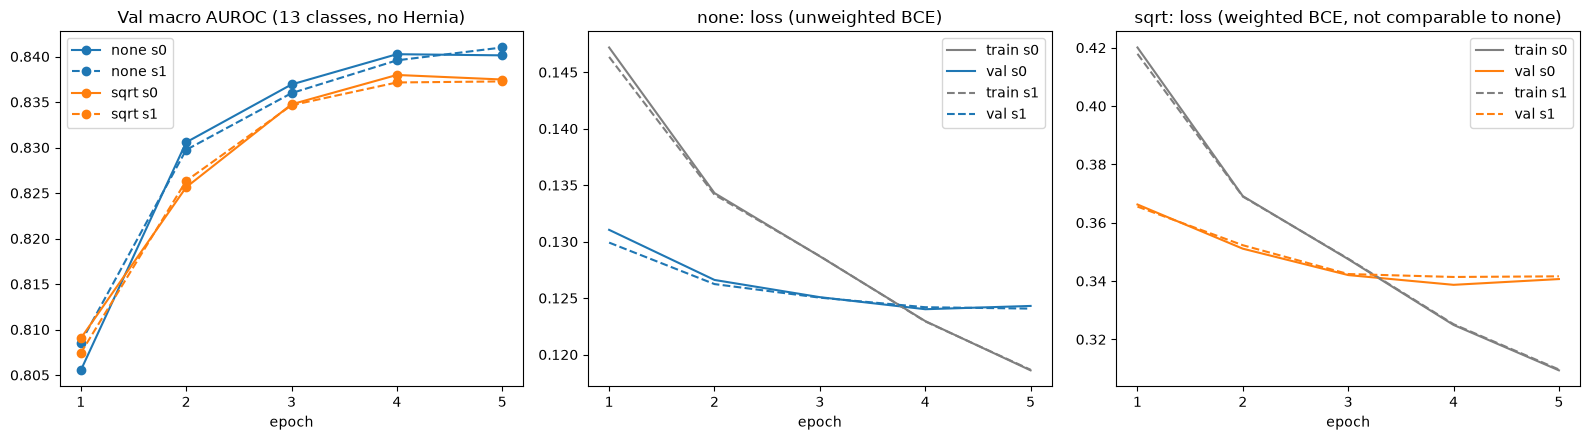

In [3]:
history = pd.concat(
    [pd.read_csv(DEV_OUTPUT_DIR / r.run_id / "history.csv").assign(pos_weight=r.pos_weight, seed=r.seed)
     for r in runs.itertuples()]
)
COLORS = {"none": "tab:blue", "sqrt": "tab:orange"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for (pw, seed), h in history.groupby(["pos_weight", "seed"]):
    style = "-" if seed == 0 else "--"
    axes[0].plot(h["epoch"], h["val_macro_auroc13"], style, color=COLORS[pw], marker="o", label=f"{pw} s{seed}")
    ax = axes[1] if pw == "none" else axes[2]
    ax.plot(h["epoch"], h["train_loss"], style, color="tab:gray", label=f"train s{seed}")
    ax.plot(h["epoch"], h["val_loss"], style, color=COLORS[pw], label=f"val s{seed}")

axes[0].set(title="Val macro AUROC (13 classes, no Hernia)", xlabel="epoch")
axes[1].set(title="none: loss (unweighted BCE)", xlabel="epoch")
axes[2].set(title="sqrt: loss (weighted BCE, not comparable to none)", xlabel="epoch")
for ax in axes:
    ax.set_xticks(range(1, 6))
    ax.legend()
plt.tight_layout()
plt.show()

## 4. Pre-declared decision rule
sqrt is adopted only if it beats none by more than the seed-to-seed spread on every seed. Ties go to none.

In [4]:
macro = runs.pivot(index="seed", columns="pos_weight", values="val_macro_auroc13")
gap = macro["sqrt"] - macro["none"]
seed_spread = (macro.max() - macro.min()).max()
adopt_sqrt = bool((gap > seed_spread).all())

print(macro)
print(f"\nsqrt - none per seed: {gap.round(4).tolist()}")
print(f"Seed spread (max over settings): {seed_spread:.4f}")
print(f"Adopt sqrt: {adopt_sqrt} -> use {'sqrt' if adopt_sqrt else 'none'}")

pos_weight    none    sqrt
seed                      
0           0.8403  0.8380
1           0.8410  0.8373

sqrt - none per seed: [-0.0023, -0.0037]
Seed spread (max over settings): 0.0007
Adopt sqrt: False -> use none


## 5. Saved logits reproduce runs.csv

In [5]:
df = load_dev_labels(NIH_DIR, SPLIT_CSV)
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"].reset_index(drop=True)
labels = val_df[NIH_DISEASES].to_numpy(dtype=float)
LOGIT_COLS = [f"logit_{d}" for d in NIH_DISEASES]

logits = {}
for r in runs.itertuples():
    saved = pd.read_csv(DEV_OUTPUT_DIR / r.run_id / "val_logits.csv")
    if not saved["Image Index"].equals(val_df["Image Index"]):
        raise RuntimeError(f"{r.run_id}: saved rows don't line up with val_df")
    logits[(r.pos_weight, r.seed)] = saved[LOGIT_COLS].to_numpy()

recomputed = pd.DataFrame({key: per_class_auroc(z, labels) for key, z in logits.items()}).T
stored = runs.set_index(["pos_weight", "seed"])[[f"auc_{d}" for d in NIH_DISEASES]]
stored.columns = NIH_DISEASES
max_diff = (recomputed - stored).abs().max().max()
print(f"Max |recomputed - stored| AUROC: {max_diff:.6f}")
if max_diff > 2e-4:
    raise RuntimeError("Saved logits don't reproduce runs.csv")

Max |recomputed - stored| AUROC: 0.000050


## 6. Per-class AUROC (mean of 2 seeds)

In [6]:
per_class = pd.DataFrame({pw: recomputed.loc[pw].mean() for pw in ["none", "sqrt"]})
per_class["sqrt - none"] = per_class["sqrt"] - per_class["none"]
per_class["val_pos"] = labels.sum(axis=0).astype(int)
per_class["selection"] = per_class.index.isin(SELECTION_CLASSES)

n_sqrt_wins = int((per_class.loc[SELECTION_CLASSES, "sqrt - none"] > 0).sum())
print(f"Selection classes where sqrt beats none: {n_sqrt_wins} / {len(SELECTION_CLASSES)}")
per_class.sort_values("sqrt - none").round(4)

Selection classes where sqrt beats none: 3 / 13


,none,sqrt,sqrt - none,val_pos,selection
Pneumonia,0.7641,0.7546,-0.0095,113,True
Nodule,0.7760,0.7678,-0.0082,564,True
Fibrosis,0.8054,0.7973,-0.0081,153,True
Infiltration,0.7232,0.7157,-0.0075,1661,True
Atelectasis,0.8315,0.8242,-0.0073,979,True
Edema,0.9228,0.9185,-0.0043,128,True
Effusion,0.9075,0.9036,-0.0038,937,True
Consolidation,0.8397,0.8380,-0.0017,309,True
Cardiomegaly,0.9344,0.9340,-0.0004,216,True
Pleural_Thickening,0.8044,0.8042,-0.0001,247,True


## 7. Calibration
Val loss in the training logs is weighted for sqrt, so both models are scored here with unweighted BCE. Prior correction subtracts log(w_sqrt) per class.

In [7]:
w_sqrt = compute_pos_weight(train_df, mode="sqrt").double().numpy()
prevalence_val = labels.mean(axis=0)


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def bce(z, y):
    return float(np.mean(np.logaddexp(0, z) - y * z))


rows = []
for (pw, seed), z in logits.items():
    versions = {"raw": z}
    if pw == "sqrt":
        versions["prior-corrected"] = z - np.log(w_sqrt)
    for name, zz in versions.items():
        mean_pred = sigmoid(zz).mean(axis=0)
        rows.append({
            "run": f"{pw} s{seed}",
            "logits": name,
            "val BCE (unweighted)": bce(zz, labels),
            "macro13": macro_auroc(per_class_auroc(zz, labels)),
            "mean pred / prevalence (median of 14)": float(np.median(mean_pred / prevalence_val)),
            "Pneumonia mean pred": float(mean_pred[NIH_DISEASES.index("Pneumonia")]),
        })

print(f"Val Pneumonia prevalence: {prevalence_val[NIH_DISEASES.index('Pneumonia')]:.4f}")
pd.DataFrame(rows).round(4)

Val Pneumonia prevalence: 0.0107


,run,logits,val BCE (unweighted),macro13,mean pred / prevalence (median of 14),Pneumonia mean pred
0,none s0,raw,0.1240,0.8403,1.0125,0.0109
1,none s1,raw,0.1241,0.8410,0.9792,0.0109
2,sqrt s0,raw,0.1701,0.8380,3.5309,0.0836
3,sqrt s0,prior-corrected,0.1243,0.8380,1.0123,0.0109
4,sqrt s1,raw,0.1677,0.8373,3.3185,0.0834
5,sqrt s1,prior-corrected,0.1248,0.8373,0.9600,0.0108


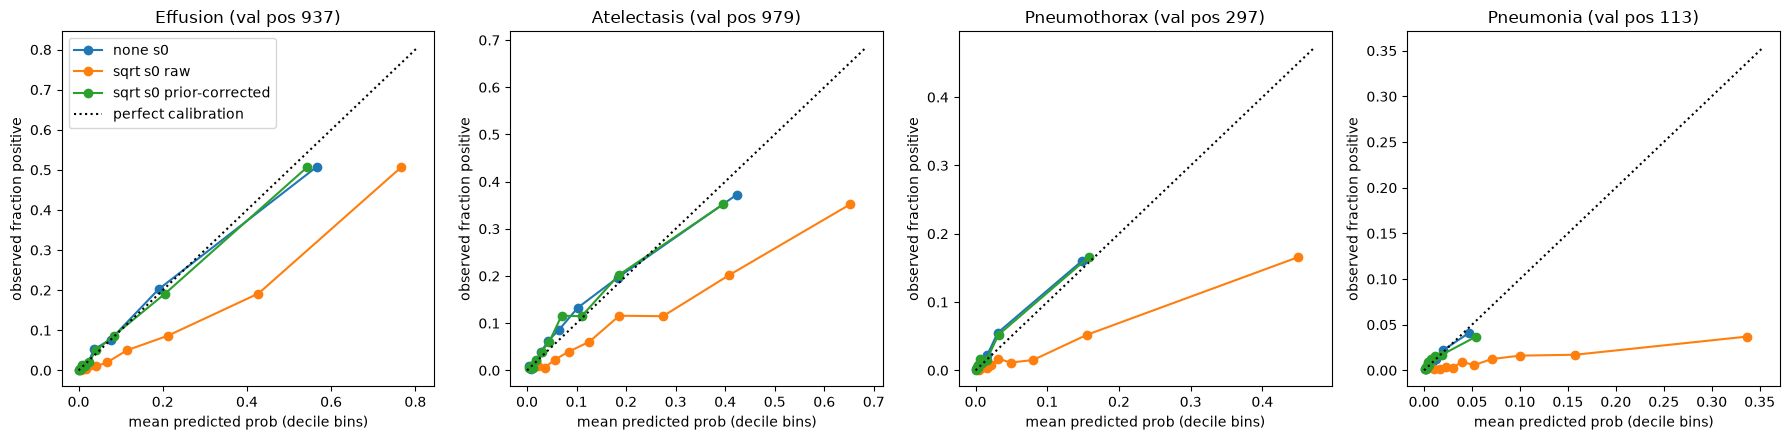

In [8]:
def reliability(ax, p, y, label, n_bins=10):
    edges = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    bins = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, n_bins - 1)
    mean_p = [p[bins == b].mean() for b in range(n_bins)]
    frac_pos = [y[bins == b].mean() for b in range(n_bins)]
    ax.plot(mean_p, frac_pos, "o-", label=label)


fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, cls in zip(axes, ["Effusion", "Atelectasis", "Pneumothorax", "Pneumonia"]):
    i = NIH_DISEASES.index(cls)
    y = labels[:, i]
    reliability(ax, sigmoid(logits[("none", 0)][:, i]), y, "none s0")
    reliability(ax, sigmoid(logits[("sqrt", 0)][:, i]), y, "sqrt s0 raw")
    reliability(ax, sigmoid(logits[("sqrt", 0)][:, i] - np.log(w_sqrt[i])), y, "sqrt s0 prior-corrected")
    top = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([0, top], [0, top], "k:", label="perfect calibration")
    ax.set(title=f"{cls} (val pos {int(y.sum())})", xlabel="mean predicted prob (decile bins)", ylabel="observed fraction positive")
axes[0].legend()
plt.tight_layout()
plt.show()

## Training decisions
- Setup: DenseNet-121 (ImageNet), FP32 head, AdamW lr 1e-4 wd 1e-2, 500-step warmup + per-step cosine, batch 64, 5 epochs, bf16 autocast. Best epoch chosen by val macro AUROC over 13 classes (no Hernia). All 4 runs at commit `97cf6d5`, `src_dirty=False`.
- Results (val macro13): none 0.8403 / 0.8410, sqrt 0.8380 / 0.8373 (seeds 0 / 1). Best epochs 4, 5, 4, 5.
- **Decision: pos_weight = none.** Pre-declared rule: sqrt only if it beats none by more than the seed spread on every seed. sqrt - none = -0.0023 / -0.0037; seed spread = 0.0007. sqrt never beats none.
- The gap is consistent across seeds (~4x the seed spread), but 2 seeds give a rough spread, and val sampling noise (patient bootstrap, milestone 7) is likely larger. Report as "no benefit from sqrt weighting", not "none is better".
- Per class: sqrt wins 3 / 13 selection classes (Mass +0.001, Pneumothorax +0.004, Emphysema +0.007) and loses 10 (worst: Pneumonia -0.0095, Nodule -0.0082, Fibrosis -0.0081).
- Hernia (22 val positives, not used for selection): sqrt 0.963 vs none 0.891. Not acted on; an open question for a pre-declared check later.
- Calibration (unweighted val BCE): none 0.1240 / 0.1241; sqrt raw 0.1701 / 0.1677; sqrt prior-corrected 0.1243 / 0.1248. Raw sqrt over-predicts ~3.5x (median mean-pred / prevalence 3.53 / 3.32; Pneumonia 0.084 vs 0.011 prevalence); subtracting log w restores ~1.0 and leaves AUROC unchanged. Weighting mainly shifted the bias; it bought no ranking.
- 5 epochs confirmed: val loss bottoms at epoch 4 in 3 of 4 runs (none s1 is flat across epochs 4-5) while train loss keeps falling; AUROC gains after epoch 4 are <= 0.0014.
- Saved val logits reproduce runs.csv AUROCs (max diff 0.00005, rounding only), so milestones 7-8 can work from the saved logits.
- Carried forward: the 2 none checkpoints (seeds 0, 1) are the candidates for milestone 7 (thresholds, bootstrap CIs, seed ensemble on val).